# Arboles de Regresion

In [1]:
import pandas as pd

In [4]:
data = pd.read_csv("../datasets/boston/Boston.csv")
data.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [5]:
data.shape

(506, 14)

In [7]:
colnames = data.columns.values.tolist()
predictors = colnames[:13]
target = colnames[13]
X = data[predictors]
Y = data[target]

In [8]:
from sklearn.tree import DecisionTreeRegressor

In [21]:
regtree = DecisionTreeRegressor(min_samples_split=30, min_samples_leaf=10, max_depth=5, random_state=0)

In [23]:
regtree.fit(X,Y)

,criterion,'squared_error'
,splitter,'best'
,max_depth,5
,min_samples_split,30
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [24]:
preds = regtree.predict(data[predictors])

In [25]:
data["preds"] = preds

In [26]:
data[["preds", "medv"]]

,preds,medv
0,23.787500,24.0
1,23.787500,21.6
2,35.247826,34.7
3,35.247826,33.4
4,35.247826,36.2
...,...,...
501,23.787500,22.4
502,23.787500,20.6
503,28.978261,23.9
504,31.170000,22.0


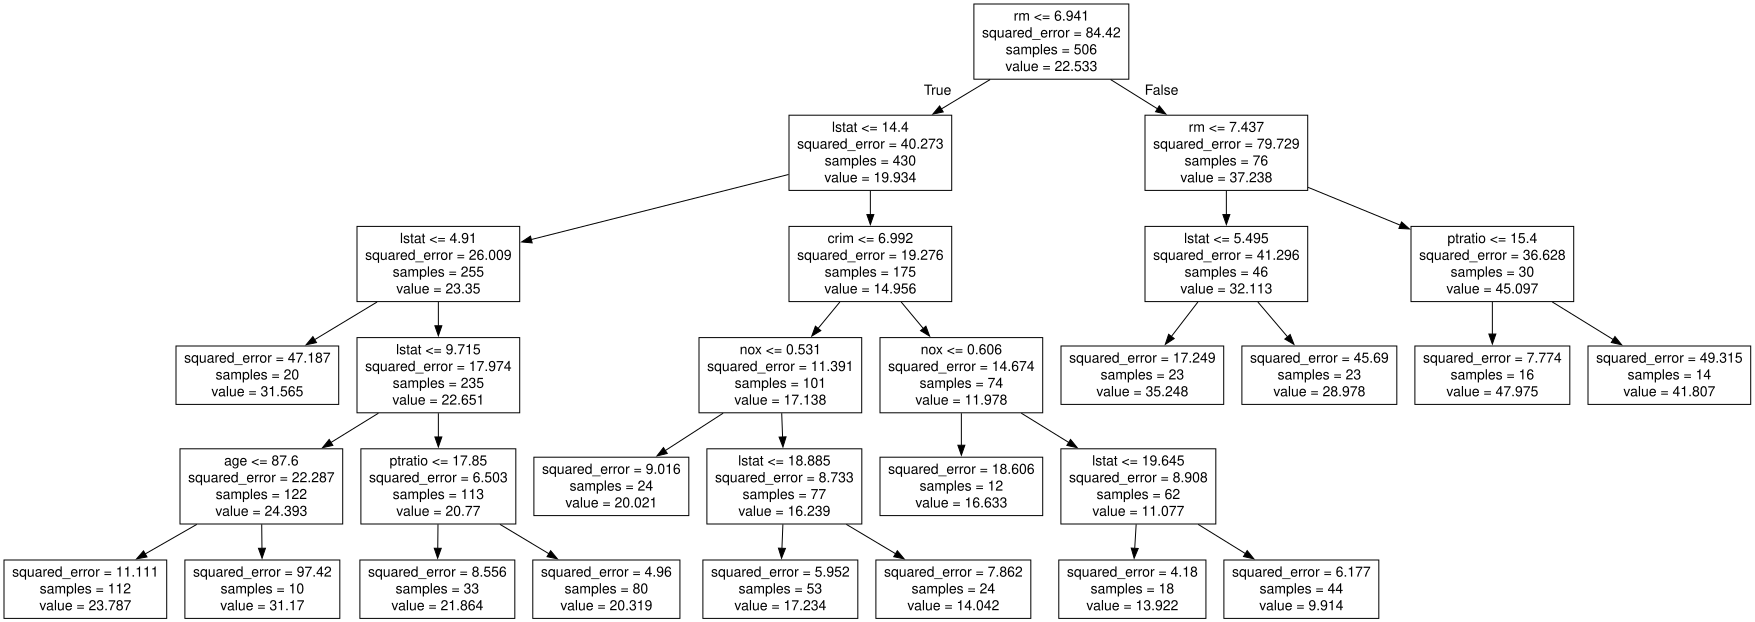

In [27]:
from sklearn.tree import export_graphviz
with open("resources/boston_rtree.dot", "w") as dotfile:
    export_graphviz(regtree, out_file=dotfile, feature_names=predictors)
    dotfile.close()
    
import os
from graphviz import Source

file = open("resources/boston_rtree.dot", "r")
text = file.read()
text

Source(text)

In [28]:
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
import numpy as np

In [29]:
cv = KFold(n_splits=10, shuffle=True, random_state=1)
scores = cross_val_score(regtree, X, Y, scoring="neg_mean_squared_error", cv = cv, n_jobs=1)
print(scores)
score = np.mean(scores)
print(score)

[-14.21501779 -16.62018743 -18.48312343 -46.22608214 -10.25202434
 -18.39546877 -15.08005674 -32.23929702 -23.04375075 -10.93761052]
-20.54926189262014


In [30]:
list(zip(predictors,regtree.feature_importances_))

[('crim', np.float64(0.032184533425691254)),
 ('zn', np.float64(0.0)),
 ('indus', np.float64(0.0)),
 ('chas', np.float64(0.0)),
 ('nox', np.float64(0.016195328299152056)),
 ('rm', np.float64(0.6341876193016562)),
 ('age', np.float64(0.014165271650613091)),
 ('dis', np.float64(0.0)),
 ('rad', np.float64(0.0)),
 ('tax', np.float64(0.0)),
 ('ptratio', np.float64(0.009620458196377114)),
 ('black', np.float64(0.0)),
 ('lstat', np.float64(0.2936467891265104))]

## Random Forests

In [31]:
from sklearn.ensemble import RandomForestRegressor

In [43]:
forest = RandomForestRegressor(n_jobs=2, oob_score=True, n_estimators=10000)
forest.fit(X,Y)

,n_estimators,10000
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,True


In [44]:
data["rforest_pred"] = forest.oob_prediction_
data[["rforest_pred", "medv"]]

,rforest_pred,medv
0,28.355460,24.0
1,22.613588,21.6
2,34.451496,34.7
3,34.710003,33.4
4,34.303977,36.2
...,...,...
501,24.178099,22.4
502,18.949673,20.6
503,27.693405,23.9
504,26.083724,22.0


In [45]:
data["rforest_error2"] = (data["rforest_pred"]-data["medv"])**2
sum(data["rforest_error2"])/len(data)

10.198507130827702

In [46]:
forest.oob_score_

0.8791925994971859